# Information Retrieval and Web Analytics

# Final Project - Part 1: Text Processing and Exploratory Data Analysis

In this notebook we:

1. **Pre-process the corpus** with the functions of `myapp/preprocessing/` (the same `build_terms()` is used for documents and queries).
2. **Study the fields** to decide how to treat them (categorical and numeric fields).
3. **Do the exploratory data analysis (EDA)** of the corpus.

The figures are saved in `project_progress/part_1/figures/`.

### 1 - Packages

In [1]:
# you may install any missing package with: "python -m pip install <package_name>"
import os
import sys
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import spacy

# the notebook is in project_progress/part_1, so the root of the project is two folders up
ROOT = "../.." if not os.path.exists("myapp") else "."
sys.path.append(ROOT)

from myapp.preprocessing.text_processing import (build_terms, tokenize, remove_numbers,
                                                 remove_stopwords, remove_short_tokens, stem_tokens)
from myapp.preprocessing.fields import (load_raw_corpus, flatten_product_details, build_processed_corpus,
                                        numeric_frame, save_processed_corpus)

DATA_PATH = os.path.join(ROOT, "data", "fashion_products_dataset.json")
LABELS_PATH = os.path.join(ROOT, "data", "validation_labels.csv")
OUTPUT_PATH = os.path.join(ROOT, "data", "processed", "processed_corpus.pkl")
FIG_PATH = os.path.join(ROOT, "project_progress", "part_1", "figures")
os.makedirs(FIG_PATH, exist_ok=True)

### 2 - Load data into memory

In [2]:
df = load_raw_corpus(DATA_PATH)
N = len(df)  # number of documents in the collection
print("Total number of documents in the corpus: {}".format(N))
print("Fields: {}".format(list(df.columns)))
df.head(3)

Total number of documents in the corpus: 28080
Fields: ['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...


#### Missing values and duplicates
A value is missing if it is None, NaN, an empty string or an empty list.

In [3]:
def count_missing(column):
    """Number of missing values (None, NaN, empty string or list) in a column of df."""
    n = 0
    for v in df[column]:
        if v is None or (isinstance(v, float) and np.isnan(v)) or (isinstance(v, (str, list)) and len(v) == 0):
            n += 1
    return n

missing = pd.DataFrame({"missing": [count_missing(c) for c in df.columns]}, index=df.columns)
missing["%"] = np.round(100 * missing["missing"] / N, 2)
missing.sort_values("missing", ascending=False)

,missing,%
description,11150,39.71
average_rating,2261,8.05
brand,2009,7.15
seller,1643,5.85
discount,855,3.04
actual_price,777,2.77
images,772,2.75
selling_price,2,0.01
_id,0,0.00
crawled_at,0,0.00


In [4]:
print("Repeated pids: {}".format(df["pid"].duplicated().sum()))
print("Different titles: {} of {} documents".format(df["title"].nunique(), N))

Repeated pids: 0
Different titles: 5953 of 28080 documents


## Part 1 - Data preparation

### 3 - Pre-processing of title and description

We apply our normalization policy (see `myapp/preprocessing/text_processing.py`) step by step to the
title + description of all the documents, and we count the vocabulary size |V| (number of different
terms) and the number of tokens after each step.

In [5]:
def vocabulary_and_tokens(docs):
    """Return (vocabulary size, number of tokens) of a list of tokenized documents."""
    vocabulary = set()
    n_tokens = 0
    for d in docs:
        vocabulary.update(d)
        n_tokens += len(d)
    return len(vocabulary), n_tokens


texts = list(df["title"].fillna("") + " " + df["description"].fillna(""))
steps = []

docs = [t.split() for t in texts]
steps.append(["0. raw text (split on spaces)", *vocabulary_and_tokens(docs)])
docs = [tokenize(t) for t in texts]
steps.append(["1. lowercase + split on punctuation", *vocabulary_and_tokens(docs)])
docs = [remove_numbers(d) for d in docs]
steps.append(["2. remove numbers", *vocabulary_and_tokens(docs)])
docs = [remove_stopwords(d) for d in docs]
steps.append(["3. remove stop words", *vocabulary_and_tokens(docs)])
docs = [remove_short_tokens(d) for d in docs]
steps.append(["4. remove one-character tokens", *vocabulary_and_tokens(docs)])
docs = [stem_tokens(d) for d in docs]
steps.append(["5. stemming (Porter)", *vocabulary_and_tokens(docs)])

pd.DataFrame(steps, columns=["step", "|V|", "tokens"])

,step,|V|,tokens
0,0. raw text (split on spaces),13521,1017425
1,1. lowercase + split on punctuation,6497,1031686
2,2. remove numbers,6326,1016181
3,3. remove stop words,6198,689771
4,4. remove one-character tokens,6181,687525
5,5. stemming (Porter),4716,687525


Some examples (the queries are processed with the same function):

In [6]:
for text in list(df["title"].head(3)) + [df["description"].iloc[0]]:
    print(text)
    print("   -> {}".format(build_terms(text)))

for query in ["women full sleeve sweatshirt cotton", "men slim jeans blue"]:
    print("query: {} -> {}".format(query, build_terms(query)))

Solid Women Multicolor Track Pants
   -> ['solid', 'women', 'multicolor', 'track', 'pant']
Solid Men Blue Track Pants
   -> ['solid', 'men', 'blue', 'track', 'pant']
Solid Men Multicolor Track Pants
   -> ['solid', 'men', 'multicolor', 'track', 'pant']
Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
   -> ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']
query: women full sleeve sweatshirt cotton -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
query: men slim jeans blue -> ['men', 'slim', 'jean', 'blue']


### 4 - Process the whole corpus and save it

For each document we keep `meta` (the fields that the results must return, with the numeric fields
converted to numbers), `tokens` (the terms of each field) and `search_tokens` (the combined field that
we will index in Part 2).

In [7]:
start_time = time.time()
corpus = build_processed_corpus(df)
save_processed_corpus(corpus, OUTPUT_PATH)
print("Total time to process the corpus: {} seconds".format(np.round(time.time() - start_time, 2)))

example = corpus[df["pid"].iloc[0]]
print("\ntokens:", example["tokens"])
print("\nsearch_tokens:", example["search_tokens"])

Total time to process the corpus: 18.93 seconds

tokens: {'title': ['solid', 'women', 'multicolor', 'track', 'pant'], 'description': ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india'], 'brand': ['york'], 'category': ['cloth', 'accessori'], 'sub_category': ['bottomwear'], 'product_details': ['elast', 'side', 'pocket', 'cotton', 'blend', 'solid', 'multicolor'], 'seller': ['shyam', 'enterpris']}

search_tokens: ['solid', 'women', 'multicolor', 'track', 'pant', 'yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india', 'york', 'bottomwear', 'elast', 'side', 'pocket', 'cotton', 'blend', 'solid', 'multicolor']


### 5 - category, sub_category, brand, seller: are they discriminative?

Rare terms are more informative than frequent terms. If a value appears in almost all the documents,
its document frequency df is close to N and its $idf = log(N/df)$ is close to 0, so it does not help to
rank. For each field we compute the number of different values, the % of documents with the most
frequent value and the idf of that value (natural log, as in the lab).

In [8]:
rows = []
for column in ["category", "sub_category", "brand", "seller"]:
    counts = df[column].fillna("").replace("", "<missing>").value_counts()
    df_top = counts.iloc[0]  # document frequency of the most frequent value
    rows.append([column, len(counts), counts.index[0], np.round(100 * df_top / N, 2), np.round(np.log(N / df_top), 4)])

pd.DataFrame(rows, columns=["field", "different values", "most frequent value", "% of documents", "idf"])

,field,different values,most frequent value,% of documents,idf
0,category,4,Clothing and Accessories,96.57,0.0349
1,sub_category,24,Topwear,54.52,0.6066
2,brand,325,<missing>,7.15,2.6374
3,seller,535,<missing>,5.85,2.8385


In [9]:
print(df["category"].value_counts(), "\n")
print(df["sub_category"].value_counts())

category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64 

sub_category
Topwear                                 15310
Bottomwear                               3666
Winter Wear                              2493
Innerwear and Swimwear                   1762
Clothing Accessories                     1742
Kurtas, Ethnic Sets and Bottoms          1180
Men's Footwear                            920
Fabrics                                   534
Sleepwear                                 122
Blazers, Waistcoats and Suits             103
Tracksuits                                 90
Raincoats                                  34
Uber Urban Clothing and Accessories        28
Inspire Clothing and Accessories           23
Sunshopping Bags, Wallets & Belts          21
Crocks Club Clothing and Accessories       15
Roy Clothing and Accessories               12
SUNSHOPPING Bags, Wallets & Belt

#### product_details
It is a list of small dictionaries (`[{"Fabric": "Cotton"}, {"Color": "Blue"}, ...]`). We look at which
attributes appear and how many different values they have.

In [10]:
details = [flatten_product_details(d) for d in df["product_details"]]
key_counts = Counter()
for d in details:
    key_counts.update(d.keys())

print("Different attributes: {}".format(len(key_counts)))
print("Mean attributes per product: {}".format(np.round(np.mean([len(d) for d in details]), 2)))

for key in ["Fabric", "Color", "Fit", "Sleeve", "Ideal For", "Style Code", "Country of Origin"]:
    values = Counter(d[key] for d in details if key in d)
    print("{}: {} products, {} different values, most common: {}".format(
        key, key_counts[key], len(values), values.most_common(3)))

Different attributes: 127
Mean attributes per product: 13.34
Fabric: 25959 products, 244 different values, most common: [('Cotton Blend', 10635), ('Pure Cotton', 4954), ('Polycotton', 2667)]
Color: 14185 products, 352 different values, most common: [('Multicolor', 2528), ('Blue', 2172), ('Black', 1951)]


Fit: 16808 products, 45 different values, most common: [('Regular', 11835), ('Slim', 3831), ('Slim Fit', 572)]
Sleeve: 18861 products, 21 different values, most common: [('Half Sleeve', 7506), ('Full Sleeve', 6372), ('Short Sleeve', 3585)]
Ideal For: 16983 products, 9 different values, most common: [('Women', 8501), ('Men', 8448), ('Women, Girls', 13)]
Style Code: 25763 products, 23263 different values, most common: [('3', 29), ('8', 26), ('cotton Printed Shirt Fabric (Unstitched)', 25)]
Country of Origin: 11659 products, 11 different values, most common: [('India', 11528), ('Namibia', 36), ('Bangladesh', 31)]


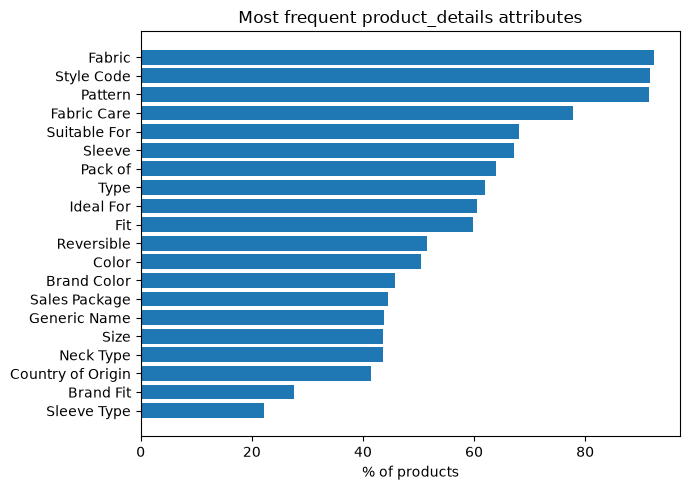

In [11]:
top_keys = key_counts.most_common(20)[::-1]
plt.figure(figsize=(7, 5))
plt.barh([k for k, c in top_keys], [100 * c / N for k, c in top_keys])
plt.title("Most frequent product_details attributes")
plt.xlabel("% of products")
plt.tight_layout()
plt.show()

### 6 - Numeric fields

`selling_price`, `actual_price`, `discount`, `average_rating` and `out_of_stock` are converted to numbers
(they are not indexed as terms). We check that the conversion works and that the values make sense.

In [12]:
num = numeric_frame(corpus)

for column in ["selling_price", "actual_price", "discount", "average_rating"]:
    print("{}: converted in {}% of the documents".format(column, np.round(100 * num[column].notna().mean(), 2)))

# the selling price should never be higher than the actual price
both = num.dropna(subset=["selling_price", "actual_price"])
print("\nselling_price <= actual_price: {}%".format(np.round(100 * np.mean(both["selling_price"] <= both["actual_price"]), 2)))

# the discount should be (actual - selling) / actual
computed_discount = 100 * (num["actual_price"] - num["selling_price"]) / num["actual_price"]
print("Median difference between computed and given discount: {}".format(
    np.round(np.nanmedian(np.abs(computed_discount - num["discount"])), 2)))

num.describe().round(2)

selling_price: converted in 99.99% of the documents
actual_price: converted in 97.23% of the documents
discount: converted in 96.96% of the documents
average_rating: converted in 91.95% of the documents

selling_price <= actual_price: 100.0%
Median difference between computed and given discount: 0.26


,selling_price,discount,actual_price,average_rating
count,28078.00,27225.00,27303.00,25819.00
mean,705.64,50.26,1455.53,3.63
std,549.68,16.89,939.98,0.66
min,99.00,1.00,150.00,1.00
25%,390.00,40.00,849.00,3.20
50%,545.00,53.00,1199.00,3.80
75%,820.00,63.00,1799.00,4.10
max,7999.00,87.00,12999.00,5.00


### 7 - Validation labels: in which fields do the query terms appear?

`validation_labels.csv` contains relevance judgments (1 = relevant, 0 = non-relevant) for two queries.
For each query, field and term we compute the % of documents that contain the term, separately for the
relevant and the non-relevant documents. This helps us to decide which fields are important.

In [13]:
labels = pd.read_csv(LABELS_PATH)
print(labels.groupby(["query_id", "labels"]).size())

queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
fields = ["title", "description", "brand", "sub_category", "product_details", "seller", "search_tokens"]

rows = []
for q_id in queries:
    query_terms = build_terms(queries[q_id])
    for relevant in [1, 0]:
        pids = labels[(labels["query_id"] == q_id) & (labels["labels"] == relevant)]["pid"]
        docs = [corpus[pid] for pid in pids]
        for field in fields:
            row = [q_id, relevant, field]
            for term in query_terms:
                if field == "search_tokens":
                    found = [term in d["search_tokens"] for d in docs]
                else:
                    found = [term in d["tokens"][field] for d in docs]
                row.append(np.round(100 * np.mean(found), 1))
            row.append(np.round(np.mean(row[3:]), 1))  # mean over the query terms
            rows.append(row)

for q_id in queries:
    columns = ["query", "relevant", "field"] + build_terms(queries[q_id]) + ["mean"]
    table = pd.DataFrame([r for r in rows if r[0] == q_id], columns=columns)
    print("\nQuery {}: '{}' (% of documents that contain each term)".format(q_id, queries[q_id]))
    print(table.to_string(index=False))

query_id  labels
1         0          7
          1         13
2         0         10
          1         10
dtype: int64

Query 1: 'women full sleeve sweatshirt cotton' (% of documents that contain each term)
 query  relevant           field  women  full  sleev  sweatshirt  cotton  mean
     1         1           title  100.0 100.0  100.0       100.0     0.0  80.0
     1         1     description   46.2  46.2   38.5        69.2    92.3  58.5
     1         1           brand    0.0   0.0    0.0         0.0     0.0   0.0
     1         1    sub_category    0.0   0.0    0.0         0.0     0.0   0.0
     1         1 product_details   23.1 100.0  100.0        84.6    84.6  78.5
     1         1          seller    0.0   0.0    0.0         0.0     0.0   0.0
     1         1   search_tokens  100.0 100.0  100.0       100.0   100.0 100.0
     1         0           title  100.0  42.9   42.9        42.9     0.0  45.7
     1         0     description   28.6  57.1   71.4        57.1   100.0  62.8


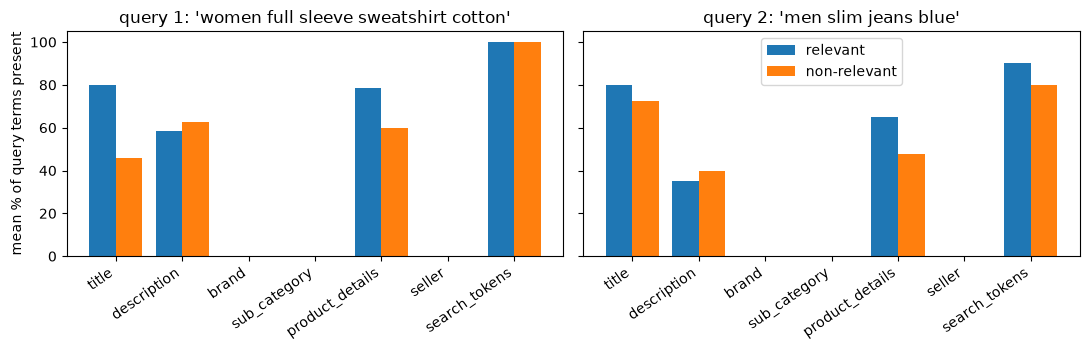

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
x = np.arange(len(fields))
for i, q_id in enumerate(queries):
    mean_relevant = [r[-1] for r in rows if r[0] == q_id and r[1] == 1]
    mean_non_relevant = [r[-1] for r in rows if r[0] == q_id and r[1] == 0]
    ax[i].bar(x - 0.2, mean_relevant, width=0.4, label="relevant")
    ax[i].bar(x + 0.2, mean_non_relevant, width=0.4, label="non-relevant")
    ax[i].set_xticks(x)
    ax[i].set_xticklabels(fields, rotation=35, ha="right")
    ax[i].set_title("query {}: '{}'".format(q_id, queries[q_id]))
ax[0].set_ylabel("mean % of query terms present")
ax[1].legend(loc="upper center")  # empty area of the plot (brand, sub_category)
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "validation_fields.png"), dpi=150)
plt.show()

## Part 2 - Exploratory Data Analysis

### 8 - Word counting distribution and average sentence length

Words per title:       mean = 6.46, median = 6.0, max = 38
Words per description: mean = 29.77, median = 10.0, max = 623
Empty descriptions: 39.71%


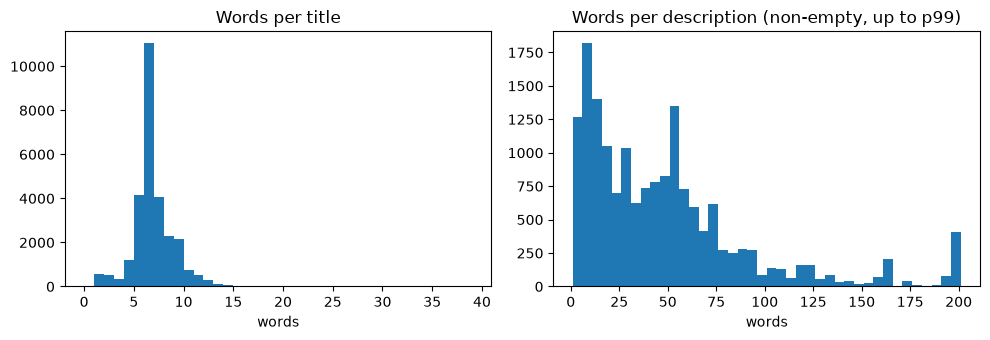

In [15]:
title_words = [len(t.split()) for t in df["title"].fillna("")]
desc_words = [len(t.split()) for t in df["description"].fillna("")]

print("Words per title:       mean = {}, median = {}, max = {}".format(
    np.round(np.mean(title_words), 2), np.median(title_words), np.max(title_words)))
print("Words per description: mean = {}, median = {}, max = {}".format(
    np.round(np.mean(desc_words), 2), np.median(desc_words), np.max(desc_words)))
print("Empty descriptions: {}%".format(np.round(100 * np.mean(np.array(desc_words) == 0), 2)))

# histogram of the non-empty descriptions, cut at the 99th percentile so the long tail does not hide the shape
non_empty = [w for w in desc_words if w > 0]
limit = np.percentile(non_empty, 99)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(title_words, bins=range(0, 40))
ax[0].set_title("Words per title")
ax[0].set_xlabel("words")
ax[1].hist([w for w in non_empty if w <= limit], bins=40)
ax[1].set_title("Words per description (non-empty, up to p99)")
ax[1].set_xlabel("words")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "word_counts.png"), dpi=150)
plt.show()

In [16]:
# we split each description into sentences on . ! ?
sentences_per_desc = []
sentence_lengths = []
for desc in df["description"].dropna():
    sentences = [s for s in re.split(r"[.!?]", desc) if len(s.split()) > 0]
    if len(sentences) == 0:
        continue
    sentences_per_desc.append(len(sentences))
    for s in sentences:
        sentence_lengths.append(len(s.split()))

print("Average sentences per description: {}".format(np.round(np.mean(sentences_per_desc), 2)))
print("Average sentence length: {} words".format(np.round(np.mean(sentence_lengths), 2)))

Average sentences per description: 3.34
Average sentence length: 14.83 words


### 9 - Vocabulary size

In [17]:
vocabulary = {}
for field in ["title", "description", "brand", "sub_category", "product_details", "seller"]:
    vocabulary[field] = Counter()
    for doc in corpus.values():
        vocabulary[field].update(doc["tokens"][field])

cf = Counter()  # collection frequency of each term in the combined field
for doc in corpus.values():
    cf.update(doc["search_tokens"])

for field in vocabulary:
    print("|V| of {}: {}".format(field, len(vocabulary[field])))
print("|V| of search_tokens (combined field): {}".format(len(cf)))
print("Mean terms per document in search_tokens: {}".format(
    np.round(np.mean([len(d["search_tokens"]) for d in corpus.values()]), 2)))

once = sum(1 for c in cf.values() if c == 1)
print("Terms that occur only once: {} ({}% of V)".format(once, np.round(100 * once / len(cf), 1)))

|V| of title: 649
|V| of description: 4557
|V| of brand: 390
|V| of sub_category: 39
|V| of product_details: 2268
|V| of seller: 672
|V| of search_tokens (combined field): 5733
Mean terms per document in search_tokens: 43.08
Terms that occur only once: 1280 (22.3% of V)


#### Zipf's law and Heaps' law
- **Zipf's law**: the rank r of a term times its probability of occurrence p(r) is approximately a constant c ($r \cdot p(r) \approx c$).
- **Heaps' law**: the vocabulary size v grows with the number of words n as $v = k \cdot n^\beta$.

To find k and β we take logs: $log(v) = log(k) + \beta \cdot log(n)$, which is a straight line, so we
fit it with a linear regression (`np.polyfit` with degree 1).

r =     1  term = neck        r*p(r) = 0.035
r =    10  term = solid       r*p(r) = 0.185
r =   100  term = crew        r*p(r) = 0.163
r =  1000  term = hot         r*p(r) = 0.079

Heaps' law: k = 2.68, beta = 0.548


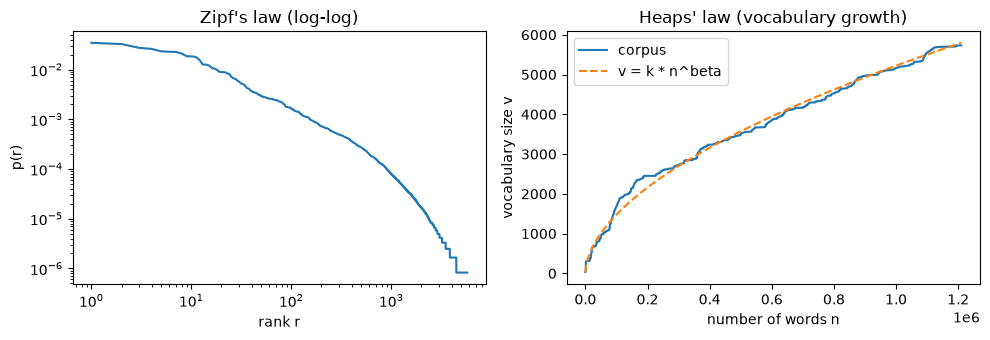

In [18]:
ranked = cf.most_common()
total = sum(cf.values())
p = np.array([c for term, c in ranked]) / total  # p(r) of each term, sorted by rank
r = np.arange(1, len(ranked) + 1)

for rank in [1, 10, 100, 1000]:
    print("r = {:5d}  term = {:10s}  r*p(r) = {}".format(rank, ranked[rank - 1][0], np.round(rank * p[rank - 1], 3)))

# Heaps' law: vocabulary size while we read the documents one by one
seen = set()
n_words = []
v_size = []
n = 0
for doc in corpus.values():
    n += len(doc["search_tokens"])
    seen.update(doc["search_tokens"])
    n_words.append(n)
    v_size.append(len(seen))

beta, log_k = np.polyfit(np.log(n_words), np.log(v_size), 1)
k = np.exp(log_k)
print("\nHeaps' law: k = {}, beta = {}".format(np.round(k, 2), np.round(beta, 3)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(r, p)
ax[0].set_title("Zipf's law (log-log)")
ax[0].set_xlabel("rank r")
ax[0].set_ylabel("p(r)")
ax[1].plot(n_words, v_size, label="corpus")
ax[1].plot(n_words, k * np.array(n_words) ** beta, "--", label="v = k * n^beta")
ax[1].set_title("Heaps' law (vocabulary growth)")
ax[1].set_xlabel("number of words n")
ax[1].set_ylabel("vocabulary size v")
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "zipf_heaps.png"), dpi=150)
plt.show()

### 10 - Most frequent words and word clouds

In [19]:
print("Top 15 terms in titles:", vocabulary["title"].most_common(15))
print("\nTop 15 terms in descriptions:", vocabulary["description"].most_common(15))

Top 15 terms in titles: [('women', 13146), ('men', 13060), ('tshirt', 12247), ('neck', 11952), ('solid', 9246), ('round', 8301), ('print', 8123), ('pack', 4839), ('blue', 4378), ('fit', 3923), ('shirt', 3591), ('black', 3503), ('casual', 2927), ('slim', 2893), ('polo', 2668)]

Top 15 terms in descriptions: [('tshirt', 14734), ('cotton', 10139), ('wear', 9353), ('comfort', 8836), ('look', 6413), ('casual', 6034), ('fit', 5831), ('made', 5643), ('fabric', 5516), ('shirt', 5367), ('print', 4888), ('women', 4655), ('design', 4301), ('sleev', 4221), ('qualiti', 4087)]


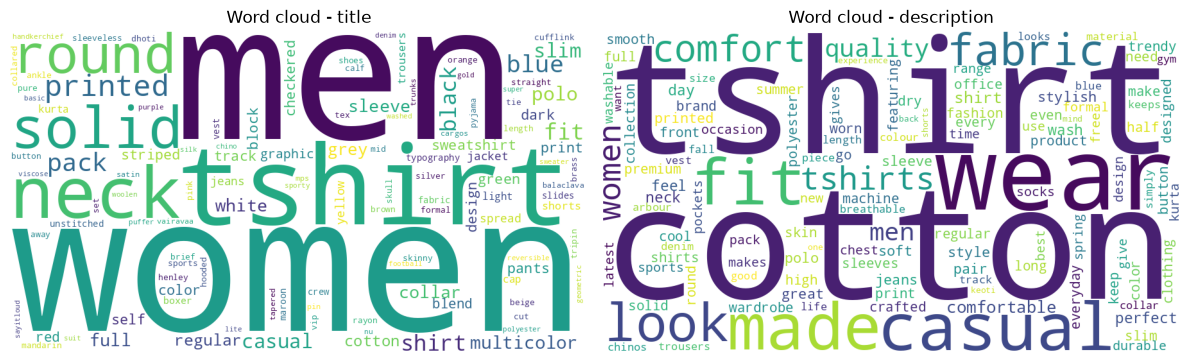

In [20]:
# for the word clouds we do not use stemming, so the words are readable
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, column in enumerate(["title", "description"]):
    words = Counter()
    for text in df[column].fillna(""):
        words.update(build_terms(text, stem=False))
    cloud = WordCloud(width=900, height=500, background_color="white", max_words=120,
                      random_state=42).generate_from_frequencies(words)
    ax[i].imshow(cloud)
    ax[i].axis("off")
    ax[i].set_title("Word cloud - " + column)
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "wordclouds.png"), dpi=150)
plt.show()

### 11 - Ranking of products by rating, price and discount

When two products have the same rating we break the tie with the discount.

In [21]:
meta = pd.DataFrame([doc["meta"] for doc in corpus.values()])
columns = ["pid", "title", "brand", "selling_price", "discount", "average_rating"]

print("Products with rating 5.0: {}".format(np.sum(meta["average_rating"] == 5)))
print("\nTop 10 by rating:")
meta.sort_values(["average_rating", "discount"], ascending=False).head(10)[columns]

Products with rating 5.0: 329

Top 10 by rating:


,pid,title,brand,selling_price,discount,average_rating
22441,KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,449.0,82.0,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,249.0,78.0,5.0
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,275.0,77.0,5.0
18497,TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,PixF,289.0,77.0,5.0
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,288.0,77.0,5.0
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,288.0,77.0,5.0
18714,TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,PixF,288.0,77.0,5.0
18738,TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18757,TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18781,TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,PixF,288.0,77.0,5.0


In [22]:
print("Top 10 most expensive:")
meta.sort_values("selling_price", ascending=False).head(10)[columns]

Top 10 most expensive:


,pid,title,brand,selling_price,discount,average_rating
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,20.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,NaN,2.6
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,40.0,3.7
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,40.0,4.5
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,40.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full S...,True Bl,6998.0,NaN,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,6925.0,36.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,39.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,50.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,35.0,NaN


In [23]:
print("Top 10 by discount:")
meta.sort_values("discount", ascending=False).head(10)[columns]

Top 10 by discount:


,pid,title,brand,selling_price,discount,average_rating
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,86.0,4.1
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,86.0,4.7
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,449.0,85.0,3.2
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",Fairdea,201.0,84.0,3.8
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,499.0,84.0,2.7
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,228.0,84.0,4.2
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,230.0,84.0,4.6
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,282.0,84.0,4.2
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,280.0,84.0,3.4


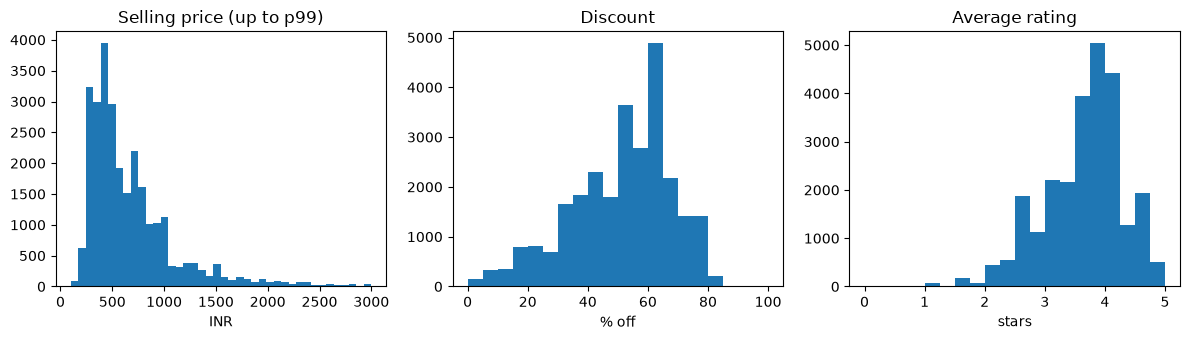

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
price = num["selling_price"].dropna()
ax[0].hist(price[price <= np.percentile(price, 99)], bins=40)
ax[0].set_title("Selling price (up to p99)")
ax[0].set_xlabel("INR")
ax[1].hist(num["discount"].dropna(), bins=range(0, 101, 5))
ax[1].set_title("Discount")
ax[1].set_xlabel("% off")
ax[2].hist(num["average_rating"].dropna(), bins=np.arange(0, 5.25, 0.25))
ax[2].set_title("Average rating")
ax[2].set_xlabel("stars")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "numeric_distributions.png"), dpi=150)
plt.show()

### 12 - out_of_stock distribution

In stock: 26436 | Out of stock: 1644 (5.9%)


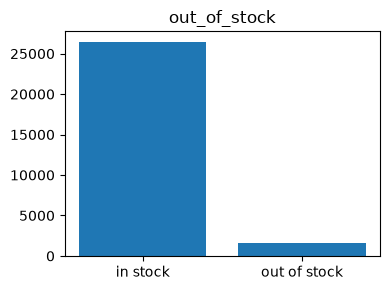

sub_category
Clothing Accessories             16.9
Tracksuits                       14.4
Winter Wear                       9.5
Sleepwear                         9.0
Bottomwear                        7.5
Blazers, Waistcoats and Suits     5.8
Innerwear and Swimwear            5.3
Topwear                           4.4
Name: out_of_stock, dtype: float64


In [25]:
in_stock = np.sum(num["out_of_stock"] == False)
out_of_stock = np.sum(num["out_of_stock"] == True)
print("In stock: {} | Out of stock: {} ({}%)".format(in_stock, out_of_stock, np.round(100 * out_of_stock / N, 1)))

plt.figure(figsize=(4, 3))
plt.bar(["in stock", "out of stock"], [in_stock, out_of_stock])
plt.title("out_of_stock")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "out_of_stock.png"), dpi=150)
plt.show()

# % of products out of stock in each sub_category
print(np.round(100 * meta.groupby("sub_category")["out_of_stock"].mean(), 1).sort_values(ascending=False).head(8))

### 13 - Top sellers and brands

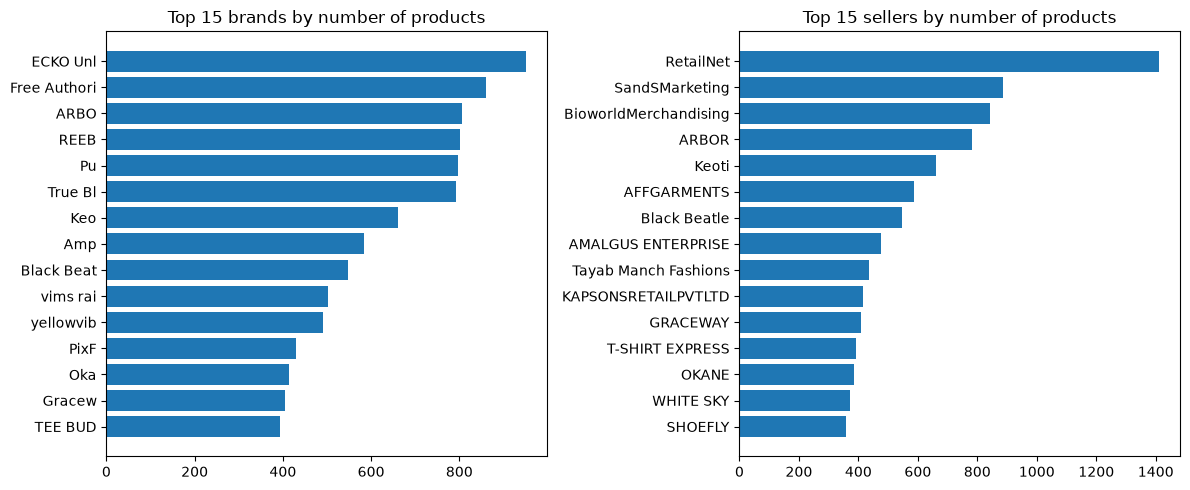

In [26]:
top_brands = meta[meta["brand"] != ""]["brand"].value_counts().head(15)
top_sellers = meta[meta["seller"] != ""]["seller"].value_counts().head(15)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(top_brands.index[::-1], top_brands.values[::-1])
ax[0].set_title("Top 15 brands by number of products")
ax[1].barh(top_sellers.index[::-1], top_sellers.values[::-1])
ax[1].set_title("Top 15 sellers by number of products")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "top_brands_sellers.png"), dpi=150)
plt.show()

In [27]:
# best rated brands: only brands with 20 products or more, to avoid brands with one or two products
brands = meta[meta["brand"] != ""].groupby("brand")
brand_table = pd.DataFrame({"products": brands.size(), "mean rating": brands["average_rating"].mean()})
brand_table[brand_table["products"] >= 20].sort_values("mean rating", ascending=False).head(10).round(2)

,products,mean rating
brand,,
VARTe,44,5.00
SORA,74,4.61
PixF,429,4.46
Cots,277,4.44
GYMBROTHE,28,4.41
Zack Fo,128,4.33
U.S.Polo As,23,4.29
Onei,57,4.23
Gracew,405,4.23


### 14 - Entity recognition

We use the named entity recognizer of spaCy (`en_core_web_sm`) on the descriptions and we look at the
classes and the most frequent entities.

In [28]:
nlp = spacy.load("en_core_web_sm")

classes = Counter()
entities = Counter()
for doc in nlp.pipe(list(df["description"].fillna("")), batch_size=256):
    for ent in doc.ents:
        classes[ent.label_] += 1
        entities[(ent.text.strip(), ent.label_)] += 1

print("Most common classes:", classes.most_common(10))
print("\nMost common entities:")
for (text, label), count in entities.most_common(25):
    print("   {:25s} {:10s} {}".format(text, label, count))

Most common classes: [('ORG', 14330), ('PERSON', 9667), ('PERCENT', 5483), ('DATE', 5425), ('GPE', 4157), ('CARDINAL', 3549), ('NORP', 1792), ('WORK_OF_ART', 1715), ('PRODUCT', 516), ('QUANTITY', 311)]

Most common entities:
   100%                      PERCENT    3005
   60%                       PERCENT    1095
   40%                       PERCENT    1048
   Cotton                    GPE        918
   kurta                     GPE        588
   Jeans                     NORP       582
   half                      CARDINAL   561
   daily                     DATE       543
   weekend                   DATE       541
   Some days                 DATE       529
   Arbour                    PERSON     431
   all day                   DATE       418
   Casual Wear               PERSON     418
   Track Pant                PERSON     400
   Printed                   ORG        382
   2                         CARDINAL   355
   3                         CARDINAL   338
   India                

### 15 - Other checks
Gender in the URL vs gender in the title and in the attribute "Ideal For".

In [29]:
title_women = df["title"].str.contains(r"\bWomen\b")
url_women = df["url"].str.contains("-women-")
url_men = df["url"].str.contains("-men-")
print("Titles with 'Women': {}".format(np.sum(title_women)))
print("   URL without 'women': {}".format(np.sum(title_women & ~url_women)))
print("   URL with '-men-': {}".format(np.sum(title_women & url_men)))

ideal_for = [d.get("Ideal For", "") for d in details]
contradictions = np.sum([(t and i == "Men") for t, i in zip(title_women, ideal_for)])
print("Titles with 'Women' and Ideal For = 'Men': {}".format(contradictions))

Titles with 'Women': 13041
   URL without 'women': 12980
   URL with '-men-': 12825
Titles with 'Women' and Ideal For = 'Men': 0
